
#### Simple Linear Regression

Import  Needed Packages

In [19]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.optimize import curve_fit
from sklearn.decomposition import PCA

Load Data

In [2]:
# Set working directory 
path = r'E:\Brain Cancer\GSE_124814\Py-Machine'
os.chdir(path)
print(os.listdir())

# Load data
data = pd.read_csv("Pro_Data.csv")

print(data.head(5))
print(data.shape)

['GSE124814_HW_expr_matrix.tsv', 'GSE124814_sample_descriptions.xlsx', 'Pro_Data.csv', 'Python-MachineLearning.ipynb']


C:\Users\Asus\AppData\Local\Temp\ipykernel_17256\970915885.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("Pro_Data.csv")


    Samples      source name gender brain region      A1CF       A2M  \
0  Sample_1  Medulloblastoma      F   cerebellum -0.019300  0.289494   
1  Sample_2  Medulloblastoma      M   cerebellum  0.059848  0.230734   
2  Sample_3  Medulloblastoma      F   cerebellum -0.092846 -0.089454   
3  Sample_4  Medulloblastoma      M   cerebellum -0.097767  0.314725   
4  Sample_5  Medulloblastoma      M   cerebellum  0.118738  1.391229   

      A2ML1    A4GALT     A4GNT      AAAS  ...    ZSWIM6    ZSWIM8      ZW10  \
0  0.213732 -0.402028  0.030517 -0.112330  ... -0.367363  0.551670  0.184700   
1  0.040908 -0.381666 -0.145988  0.092463  ... -1.109660  0.286734 -0.076648   
2 -0.086623 -0.586763 -0.245097 -0.015891  ...  0.427460  0.234605 -0.115306   
3 -0.094998 -0.784063 -0.297410  0.557690  ... -0.266578 -0.898953  0.511287   
4  0.038038 -0.242232 -0.050874  0.067459  ... -0.718445  0.300914  0.471590   

     ZWILCH     ZWINT      ZXDC    ZYG11A    ZYG11B       ZYX      ZZZ3  
0  0.754473 

### Understanding Data

* samples: include number of samples derived frome pationts and normal cases
* source name: Medulloblastoma(cancer type) and normal
* gender: M(male) and F(female)
* brain region: the area of the brain where the cancer has develope 

Differential expression analysis was performed to identify genes with significant expression changes between tumor and normal samples. Two genes of interest emerged from this analysis:

| Gene | logFC | AveExpr | t-statistic | P-value | adj.P-value | B-statistic | Significance |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | :--- |
| **ITPR1** | -1.15 | 3.52e-4 | -21.77 | 1.70×10⁻⁹² | 1.26×10⁻⁸⁸ | 199.97 | Down-regulated |
| **TOP2A** | +1.52 | 2.89e-3 | +21.47 | 2.67×10⁻⁹⁰ | 7.95×10⁻⁸⁷ | 194.95 | Up-regulated |

The results indicate that:

* ITPR1 is significantly down-regulated in tumor samples compared to normal samples (logFC = -1.15, adj.P.Val = 1.26e-88).

* TOP2A is significantly up-regulated in tumor samples compared to normal samples (logFC = +1.52, adj.P.Val = 7.95e-87).

Both genes show highly significant differential expression (adj.P.Val < 0.001) with strong statistical evidence (|t| > 21).

Research Question: Given the opposite expression patterns of ITPR1 (down-regulated) and TOP2A (up-regulated), is there a regression relationship between these two genes? Can ITPR1 expression be used to predict TOP2A expression?

Visualization

C:\Users\Asus\AppData\Local\Temp\ipykernel_17256\30610060.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([ITPR1_Normal, ITPR1_Medulloblastoma], labels=["Normal", "Medulloblastoma"], patch_artist=True)


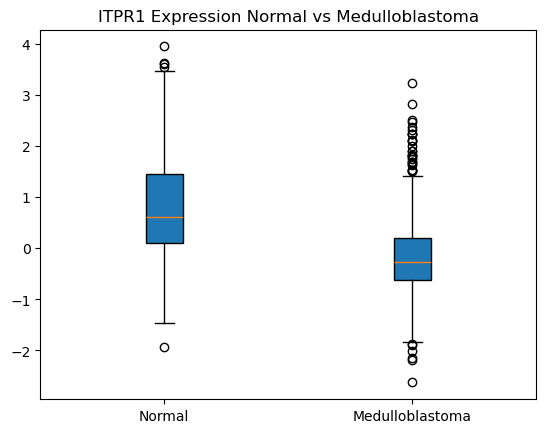

In [3]:
# ITPR1 Expression Normal vs Medulloblastoma
ITPR1_Normal = data[data["source name"] == "Normal"]["ITPR1"]
ITPR1_Medulloblastoma = data[data["source name"] == "Medulloblastoma"]["ITPR1"]

plt.boxplot([ITPR1_Normal, ITPR1_Medulloblastoma], labels=["Normal", "Medulloblastoma"], patch_artist=True)
plt.title("ITPR1 Expression Normal vs Medulloblastoma")
plt.show()

# TIPR1 is downregulated in Medulloblastoma

C:\Users\Asus\AppData\Local\Temp\ipykernel_17256\1406183687.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([TOP2A_Normal, TOP2A_Medulloblastoma], labels=["Normal", "Medulloblastoma"], patch_artist=True)


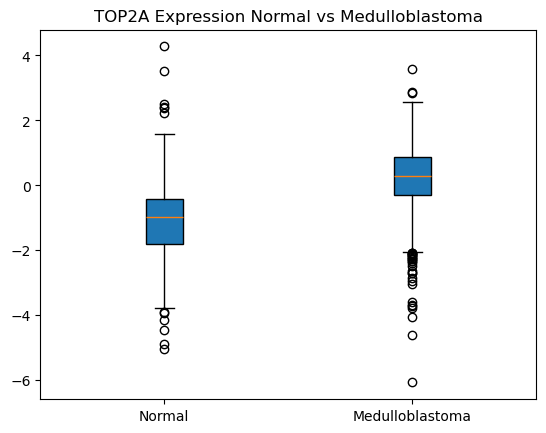

In [4]:
# TOP2A Expression Normal vs Medulloblastoma
TOP2A_Normal = data[data["source name"] == "Normal"]["TOP2A"]
TOP2A_Medulloblastoma = data[data["source name"] == "Medulloblastoma"]["TOP2A"]

plt.boxplot([TOP2A_Normal, TOP2A_Medulloblastoma], labels=["Normal", "Medulloblastoma"], patch_artist=True)
plt.title("TOP2A Expression Normal vs Medulloblastoma")
plt.show()

# TOP2A is upregulated in Medulloblastoma

         ITPR1     TOP2A
0    -0.968777  0.551231
1    -1.103583  3.574893
2    -0.774407  2.244021
3    -1.672455  2.399322
4    -0.944743  0.485011
...        ...       ...
1172  2.466370 -1.823574
1173  0.276406 -0.895962
1174  0.654937 -1.372658
1175  0.189005 -1.043854
1176  0.960757 -0.773559

[1177 rows x 2 columns]


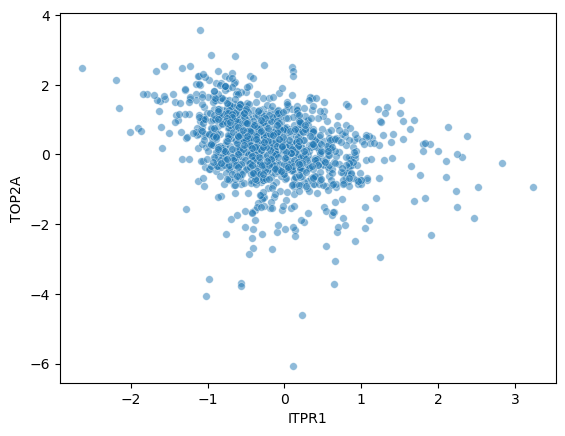

In [5]:

com_gene = pd.DataFrame({
    "ITPR1" : ITPR1_Medulloblastoma.values,
    "TOP2A" : TOP2A_Medulloblastoma.values
})
print(com_gene)

sns.scatterplot(data=com_gene, x="ITPR1", y="TOP2A", alpha=0.5, s=30)
plt.show()

       gene  expression
0     ITPR1   -0.968777
1     ITPR1   -1.103583
2     ITPR1   -0.774407
3     ITPR1   -1.672455
4     ITPR1   -0.944743
...     ...         ...
2349  TOP2A   -1.823574
2350  TOP2A   -0.895962
2351  TOP2A   -1.372658
2352  TOP2A   -1.043854
2353  TOP2A   -0.773559

[2354 rows x 2 columns]


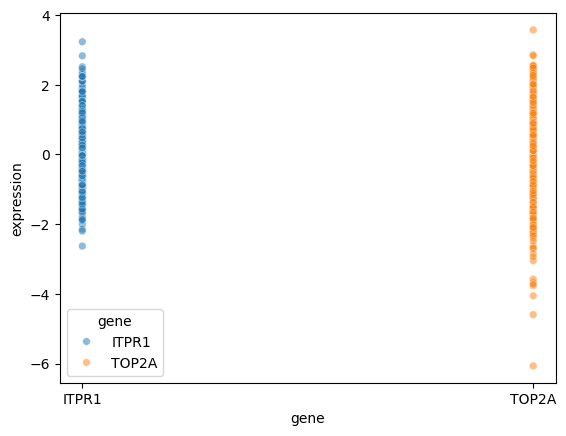

In [6]:
com_gene_long = com_gene.melt(var_name="gene", value_name="expression")
print(com_gene_long)

sns.scatterplot(data=com_gene_long, x="gene", y="expression", hue="gene", alpha=0.5, s=30)
plt.show()

#### Fit Model

      ITPR1     TOP2A
0 -0.968777  0.551231
1 -1.103583  3.574893
2 -0.774407  2.244021
3 -1.672455  2.399322
4 -0.944743  0.485011


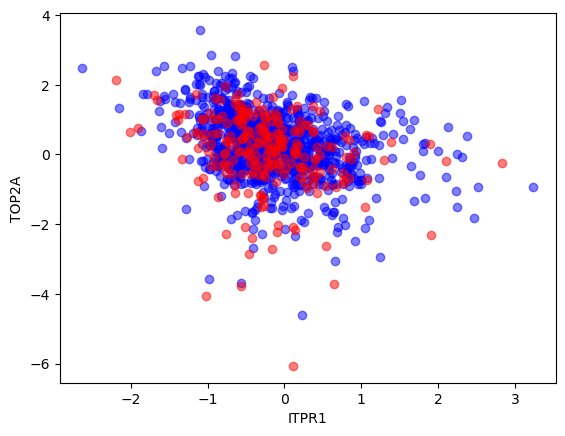

Coefficients:  [-0.32956303]
intercept:  0.29136342680127525
Mean absolute error (MAE): 0.78
Residual sum of squares (MSE): 1.25
R2-score: 0.01


In [ ]:

print(com_gene.head(5))

X_simple = com_gene[["ITPR1"]]
y = com_gene["TOP2A"]

# Data division
X_train, X_test, y_train, y_test =  train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Plot
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(X_train, y_train, alpha=0.5, color="blue")
ax.scatter(X_test, y_test, alpha=0.5, color="red")
plt.xlabel("ITPR1")
plt.ylabel("TOP2A")
plt.show(1)

# Scale Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Simple Linear Regression Model
model_simple = LinearRegression()
model_simple.fit(X_train_scaled, y_train)
y_pred_simple = model_simple.predict(X_test_scaled)

print("Coefficients: ", model_simple.coef_)
print("intercept: ", model_simple.intercept_)

# Evaluation
print("Mean absolute error (MAE): %.2f" % np.mean(np.absolute(y_test - y_pred_simple)))
print("Residual sum of squares (MSE): %.2f" % np.mean((y_test - y_pred_simple)**2))
print("R2-score: %.2f" % r2_score(y_test, y_pred_simple))




A simple linear regression predicting TOP2A from ITPR1 yielded a slope of -0.33 and an intercept of 0.29. The model's R² was only 0.01, indicating that ITPR1 explains just 1% of the variance in TOP2A. With MAE = 0.78 and MSE = 1.25, the model has no practical predictive value. These results suggest no meaningful linear relationship between the two genes, and a multivariate approach is needed for better prediction